In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df = pd.read_csv('Heart_disease_cleveland_new.csv')

In [50]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


In [51]:
df.shape

(303, 14)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [53]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,2.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,0.600660,0.663366,1.831683,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,0.956705,0.499120
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,2.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,2.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,1.000000,0.000000
75%,61.000000,1.000000,3.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,1.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,3.000000,3.000000,1.000000


In [54]:
missing = df.isnull().sum()

In [55]:
missing[missing>0]

Series([], dtype: int64)

In [56]:
missing_col = df.select_dtypes(include=np.number).columns

df[missing_col] = df[missing_col].fillna(
    df[missing_col].median()
)

In [57]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [58]:
df['target'].unique()

array([0, 1])

In [59]:
df["target"].value_counts()

target
0    164
1    139
Name: count, dtype: int64

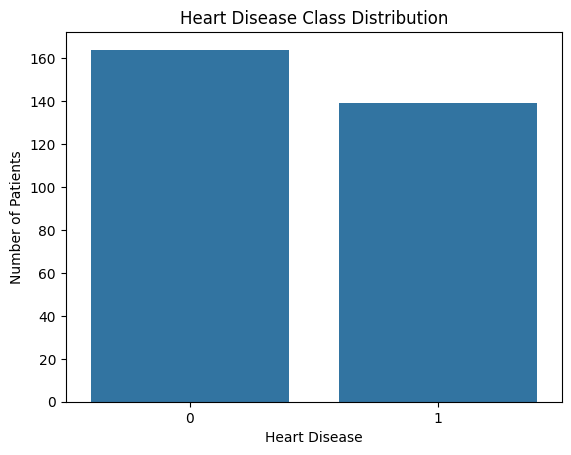

In [60]:
sns.countplot(x="target", data=df)
plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.show()

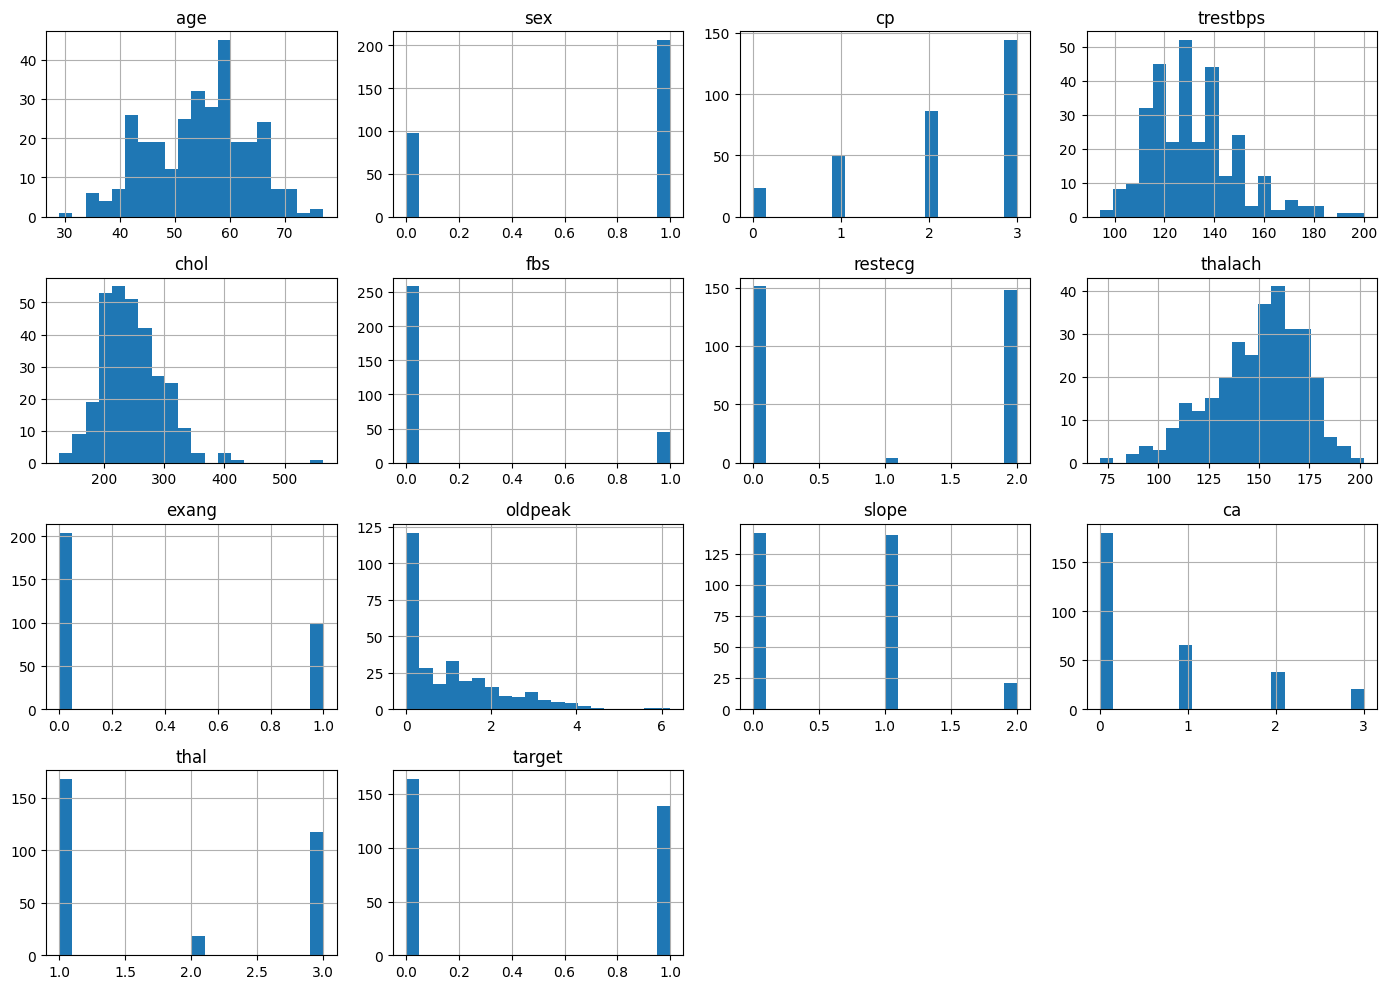

In [61]:
df.hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

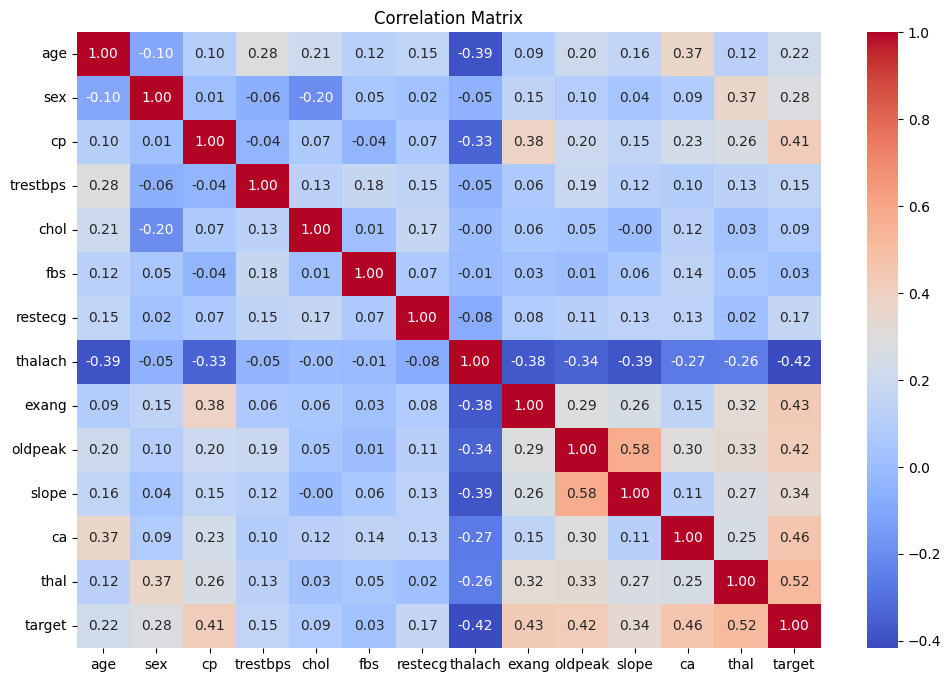

In [62]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

In [63]:
x = df.drop('target', axis=1)
y= df['target']

In [64]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.2, random_state=42)

In [65]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

In [66]:
x_train_scaled

array([[-2.83850353,  0.72250438, -1.10468954, ..., -0.96343165,
        -0.71586852, -0.84923193],
       [ 0.24135234,  0.72250438, -0.09205746, ..., -0.96343165,
         0.40181007,  1.25860528],
       [ 1.56129057,  0.72250438, -2.11732162, ...,  0.65566876,
         0.40181007, -0.84923193],
       ...,
       [ 0.46134205,  0.72250438,  0.92057462, ..., -0.96343165,
         0.40181007,  1.25860528],
       [ 0.68133175,  0.72250438,  0.92057462, ..., -0.96343165,
         0.40181007,  1.25860528],
       [ 0.24135234, -1.38407465,  0.92057462, ..., -0.96343165,
         0.40181007, -0.84923193]], shape=(242, 13))

In [67]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42)

model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)
y_prob = model.predict_proba(x_test_scaled)[:, 1]

In [68]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {(accuracy*100):.2f} %")

Accuracy: 88.52 %


In [69]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC AUC:", roc_auc)

ROC AUC: 0.9213362068965516


[[25  4]
 [ 3 29]]


<Figure size 700x600 with 0 Axes>

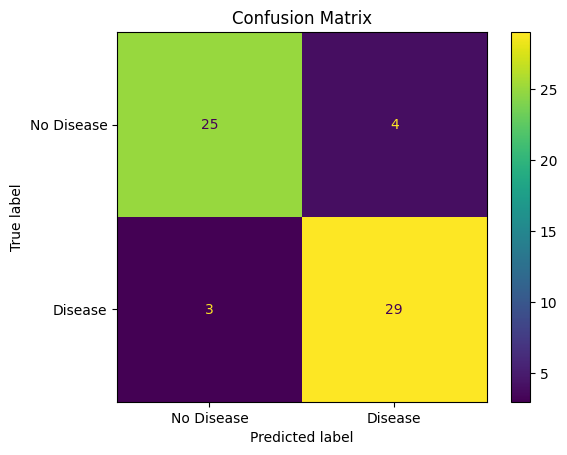

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

### ROC AUC Curve

In [71]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

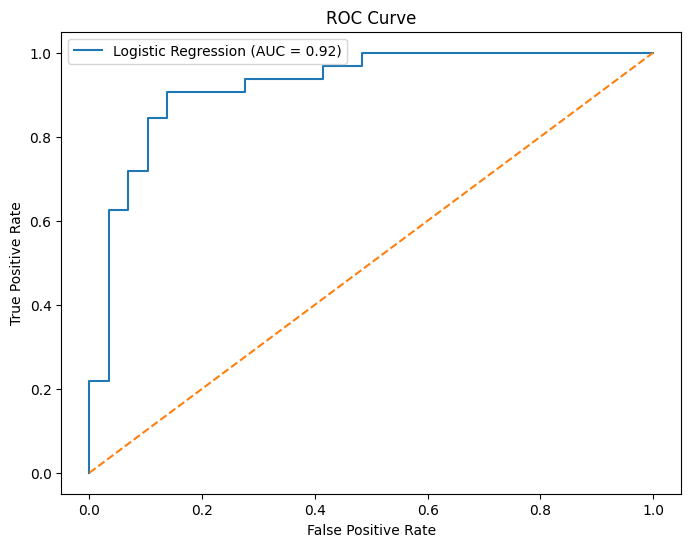

In [72]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.savefig("aur_roc.png")
plt.show()

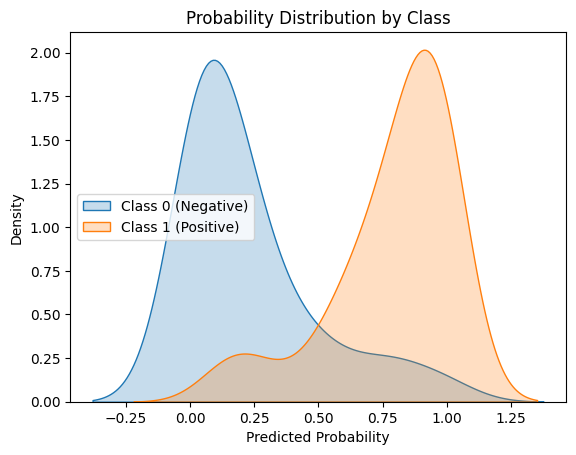

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

# This produces overlapping bell-shaped curves (probability distributions)
sns.kdeplot(y_prob[y_test == 0], label="Class 0 (Negative)", fill=True)
sns.kdeplot(y_prob[y_test == 1], label="Class 1 (Positive)", fill=True)
plt.xlabel("Predicted Probability")
plt.ylabel("Density")
plt.title("Probability Distribution by Class")
plt.legend()
plt.show()

# Signal data ingestion (ECG) 

In [74]:
# !pip install wfdb

In [75]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Step 1 & 2: Fetch and Load the Signal and Annotation
# ---------------------------------------------------------
# pn_dir='mitdb' fetches the data directly from the PhysioNet online database
record_name = '100'
record = wfdb.rdrecord(record_name, pn_dir='mitdb')
annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

# Extract the first channel (usually Modified Lead II - MLII) and sampling frequency
ecg_signal = record.p_signal[:, 0]
fs = record.fs  # 360 Hz for MIT-BIH


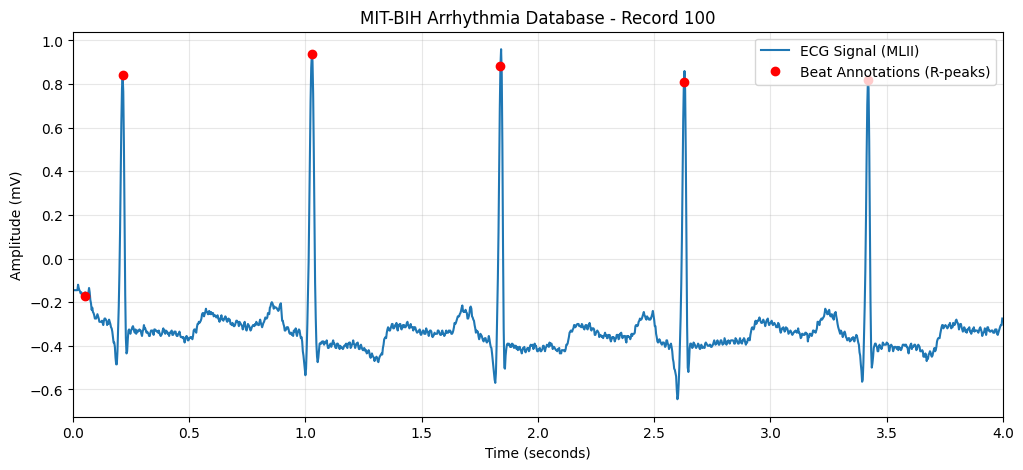

In [76]:
# ---------------------------------------------------------
# Step 3: Plot a Segment of ECG Waveform with Annotations
# ---------------------------------------------------------
# Define a window to plot (e.g., first 1440 samples = 4 seconds)
start_idx = 0
end_idx = int(4 * fs) 

time_axis = np.arange(start_idx, end_idx) / fs
segment_signal = ecg_signal[start_idx:end_idx]

# Isolate annotations that fall strictly within our chosen segment window
ann_samples = annotation.sample
segment_anns = ann_samples[(ann_samples >= start_idx) & (ann_samples < end_idx)]
segment_ann_times = segment_anns / fs
segment_ann_amps = ecg_signal[segment_anns]

plt.figure(figsize=(12, 5))
plt.plot(time_axis, segment_signal, label='ECG Signal (MLII)', color='#1f77b4', linewidth=1.5)
plt.plot(segment_ann_times, segment_ann_amps, 'ro', markersize=6, label='Beat Annotations (R-peaks)')

plt.title(f"MIT-BIH Arrhythmia Database - Record {record_name}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.xlim([0, 4])
plt.show()



In [77]:
# ---------------------------------------------------------
# Step 4: Compute Basic Heart-Rate Variability (HRV) Stats
# ---------------------------------------------------------
# Calculate RR intervals (the difference in samples between consecutive beats)
rr_intervals_samples = np.diff(ann_samples)

# Convert RR intervals from samples to seconds
rr_intervals_sec = rr_intervals_samples / fs

# Compute statistics
mean_rr = np.mean(rr_intervals_sec)
sdnn = np.std(rr_intervals_sec)  # Standard Deviation of Normal-to-Normal intervals
mean_hr = 60.0 / mean_rr         # Beats per minute (BPM)

print("--- Beat Interval Statistics (HRV) ---")
print(f"Total Beats Analyzed: {len(ann_samples)}")
print(f"Sampling Frequency:   {fs} Hz")
print(f"Mean RR Interval:     {mean_rr:.4f} seconds")
print(f"RR Std Dev (SDNN):    {sdnn:.4f} seconds")
print(f"Average Heart Rate:   {mean_hr:.1f} BPM")

--- Beat Interval Statistics (HRV) ---
Total Beats Analyzed: 2274
Sampling Frequency:   360 Hz
Mean RR Interval:     0.7943 seconds
RR Std Dev (SDNN):    0.0506 seconds
Average Heart Rate:   75.5 BPM


# Textual data demonstration

In [1]:
import nltk
import re
from collections import Counter
import matplotlib.pyplot as plt

# Download required NLTK data
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Synthetic clinical note
clinical_note = """
Patient presents with severe chest pain radiating to the left arm. 
Patient has a history of hypertension, elevated cholesterol, and smoking. 
Resting ECG shows ST depression. Patient is advised to undergo an angiography 
for further evaluation of potential heart disease.
"""


In [9]:

document = sent_tokenize(clinical_note)


stop_words = set(stopwords.words('english'))
stop_words.remove('not')

ps = PorterStemmer()


corpus = []

for sent in document:
    sent = sent.lower()
    sent = re.sub(r'[^a-zA-Z0-9]', " ", sent)
    words = word_tokenize(sent)
    words = [word for word in words if word not in stop_words]
    words = [ps.stem(word) for word in words]
    sent = " ".join(words)
    corpus.append(sent)
corpus

['patient present sever chest pain radiat left arm',
 'patient histori hypertens elev cholesterol smoke',
 'rest ecg show st depress',
 'patient advis undergo angiographi evalu potenti heart diseas']

In [10]:
all_words = []

for sent in corpus:
    all_words.extend(sent.split())

word_freq = Counter(all_words)

key_terms = word_freq.most_common(5)


In [12]:
print("--- Textual Data NLP Processing ---")

print("\nOriginal Sentences:")
for sent in document:
    print(sent)

print("\nProcessed Corpus:")
for sent in corpus:
    print(sent)

print("\nTop 5 Key Terms (Frequencies):")
for term, freq in key_terms:
    print(f"- {term}: {freq}")

--- Textual Data NLP Processing ---

Original Sentences:

Patient presents with severe chest pain radiating to the left arm.
Patient has a history of hypertension, elevated cholesterol, and smoking.
Resting ECG shows ST depression.
Patient is advised to undergo an angiography 
for further evaluation of potential heart disease.

Processed Corpus:
patient present sever chest pain radiat left arm
patient histori hypertens elev cholesterol smoke
rest ecg show st depress
patient advis undergo angiographi evalu potenti heart diseas

Top 5 Key Terms (Frequencies):
- patient: 3
- present: 1
- sever: 1
- chest: 1
- pain: 1


In [6]:
'not' in stop_words

False

In [7]:
stop_words.discard ('not')

# Image data demonstration

--- Image Metadata ---
Format: Synthetic (Array)
Original Size: (256, 256)
Mode: L
Resized to: (128, 128)


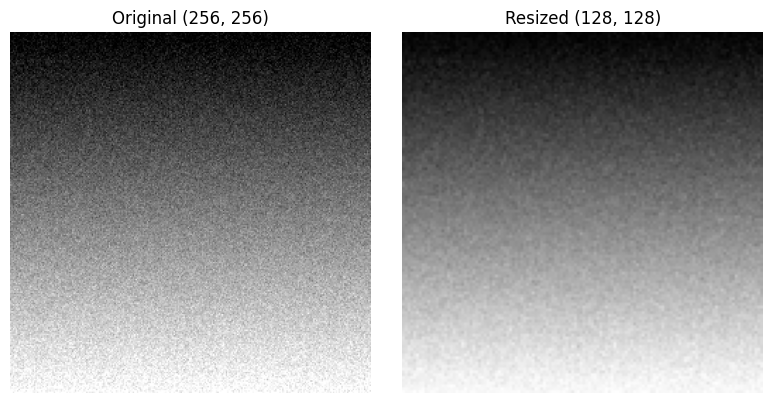

In [8]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a synthetic medical image (gradient with noise representing tissue)
array_img = np.linspace(0, 255, 256*256).reshape(256, 256)
noise = np.random.normal(0, 15, (256, 256))
synthetic_pixels = np.clip(array_img + noise, 0, 255).astype(np.uint8)

# Load into Pillow
img = Image.fromarray(synthetic_pixels, mode='L')

# 2. Extract basic metadata
metadata = {
    "Format": img.format or "Synthetic (Array)",
    "Original Size": img.size,
    "Mode": img.mode
}

# 3. Resize preprocessing
img_resized = img.resize((128, 128))

# Display the results
print("--- Image Metadata ---")
for key, value in metadata.items():
    print(f"{key}: {value}")
print(f"Resized to: {img_resized.size}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img, cmap='gray')
axes[0].set_title(f"Original {img.size}")
axes[0].axis('off')

axes[1].imshow(img_resized, cmap='gray')
axes[1].set_title(f"Resized {img_resized.size}")
axes[1].axis('off')

plt.tight_layout()
plt.show()